# Подготовка модели распознавания рукописных букв и цифр

Вам предстоит самостоятельно обучить модель для задачи распознавания рукописных букв и цифр с помощью датасета `emnist`. Результатом должна быть обученная модель, сохранённая в файл `model.pkl`.

Можете воспользоваться предложенным порядком действий и подсказками из этого ноутбука или подойти к решению задачи самостоятельно и написать всё с нуля. То же касается и процесса упаковки модели в сервис для распознавания самостоятельно написанных символов.

В этом ноутбуке комментариями и символами `...` отмечены места для вашего кода.

Перед отправкой решения убедитесь, что все ячейки ноутбука выполняются последовательно без ошибок, если запустить `Kernel -> Restart & Run All`.

Успехов!

### 1. Установите и импортируйте необходимые библиотеки

In [1]:
from collections import defaultdict
!pip install emnist
# your pip installs here

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [emnist]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [31]:
import os
import pickle
import emnist
import shutil
import struct
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [12]:
def short_parse_idx(data):
    dims = data[3]  # Количество измерений
    sizes = struct.unpack(f">{dims}I", data[4:4 + 4 * dims])
    return np.frombuffer(data[4 + 4 * dims:], dtype=np.uint8).reshape(sizes)

emnist.parse_idx = short_parse_idx

### 2. Загрузка датасета

Датасет в качестве лейблов (или таргетов) содержит числа от 0 до 46. Каждому числу соответствует ASCII-код некоторого символа. Пары «лейбл — код» хранятся в файле `emnist-balanced-mapping.txt`.
Выведите на экран количество семплов в каждом сплите датасета и размер изображений. Также для каждого лейбла выведите соответствующий ему символ и количество тренировочных семплов, приходящееся на него.
Посмотрите на несколько примеров изображений.

_Подсказка: чтобы получить символ из ASCII-кода, нужно воспользоваться функцией_ `chr()`. _Для вашего удобства можно построить словарь_ (`dict`) _соответствий._

In [14]:
images_train, labels_train = emnist.extract_training_samples('balanced')
images_test, labels_test = emnist.extract_test_samples('balanced')
print(f'Train: {images_train.shape} samples')
print(f'Test: {images_test.shape} samples')
print(f'Image size: {images_train.shape[1:]}')

Train: (112800, 28, 28) samples
Test: (18800, 28, 28) samples
Image size: (28, 28)


In [15]:
mapping = {}
with open('emnist-balanced-mapping.txt', 'r') as file:
    for line in file:
        parts = line.split()
        label = int(parts[0])
        ascii_code = int(parts[1])
        mapping[label] = chr(ascii_code)

Лейбл | Символ | Количество
----------------------------
    0 | 0      |       2400
    1 | 1      |       2400
    2 | 2      |       2400
    3 | 3      |       2400
    4 | 4      |       2400
    5 | 5      |       2400
    6 | 6      |       2400
    7 | 7      |       2400
    8 | 8      |       2400
    9 | 9      |       2400
   10 | A      |       2400
   11 | B      |       2400
   12 | C      |       2400
   13 | D      |       2400
   14 | E      |       2400
   15 | F      |       2400
   16 | G      |       2400
   17 | H      |       2400
   18 | I      |       2400
   19 | J      |       2400
   20 | K      |       2400
   21 | L      |       2400
   22 | M      |       2400
   23 | N      |       2400
   24 | O      |       2400
   25 | P      |       2400
   26 | Q      |       2400
   27 | R      |       2400
   28 | S      |       2400
   29 | T      |       2400
   30 | U      |       2400
   31 | V      |       2400
   32 | W      |       2400
   33 | X      |   

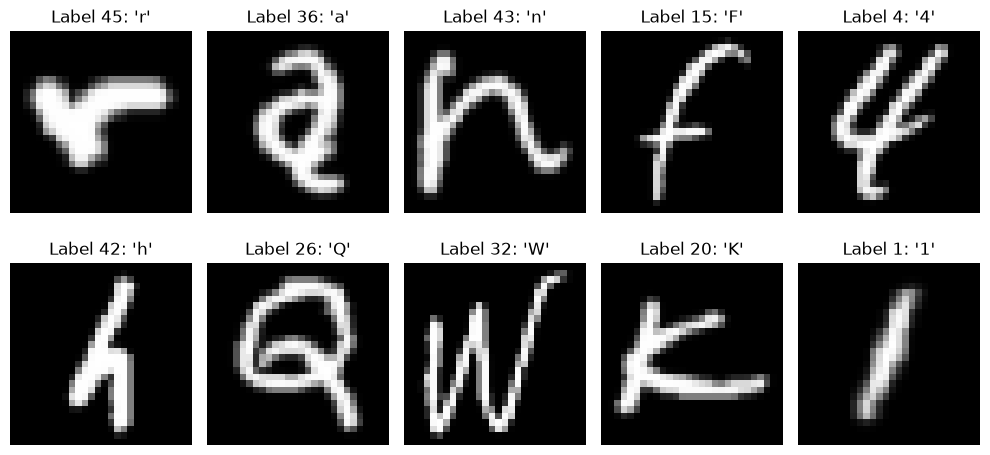

In [18]:
counts = np.bincount(labels_train)

print("Лейбл | Символ | Количество")
print("-" * 28)
for label, count in enumerate(counts):
    char = mapping[label]
    print(f"{label:5d} | {char:6s} | {count:10d}")

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_train[i], cmap='gray')
    symbol = mapping[labels_train[i]]
    ax.set_title(f"Label {labels_train[i]}: '{symbol}'")
    ax.axis('off')

plt.tight_layout()
plt.show()

### 3. Подготовьте датасет для обучения и валидации

_Подсказка: чтобы вытянуть изображения в вектор, понадобится метод_ `reshape` _из библиотеки_ `numpy`.

In [20]:
X_train = images_train.reshape(images_train.shape[0], -1)
y_train = labels_train
X_test = images_test.reshape(images_test.shape[0], -1)
y_test = labels_test

print('Train:', X_train.shape)
print('Test:', X_test.shape)

Train: (112800, 784)
Test: (18800, 784)


### 4. Выберите модель, обучите её, протестируйте и сохраните

Выведите на экран точность вашей модели. Выведите и проанализируйте матрицу ошибок. Какие два символа она чаще всего путает? На каком символе модель чаще всего ошибается?

In [32]:
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0
models = {
    "MLPClassifier (128)": MLPClassifier(hidden_layer_sizes=(128,), max_iter=30, random_state=42),
    "MLPClassifier (256, 128)": MLPClassifier(hidden_layer_sizes=(256, 128), max_iter=30, random_state=42),
    "RandomForest (100)": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
}

best_acc = 0
best_model_name = ""
best_clf = None

for name, model in models.items():
    print(f"Обучение {name}...")
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"Точность {name}: {acc * 100:.2f}%\n")

    if acc > best_acc:
        best_acc = acc
        best_model_name = name
        best_clf = model

print(f"Лучшая модель: {best_model_name} с точностью {best_acc * 100:.2f}%")

y_pred_best = best_clf.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

true_label, pred_label = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)
worst_label = np.argmax(cm_no_diag.sum(axis=1))

print(f"Чаще всего модель путает '{mapping[true_label]}' с '{mapping[pred_label]}' ({cm_no_diag[true_label, pred_label]} раз)")
print(f"Больше всего ошибок на символе: '{mapping[worst_label]}'")

os.makedirs('myapp', exist_ok=True)
with open(os.path.join('myapp', 'model.pkl'), 'wb') as f:
    pickle.dump(best_clf, f)
print("Победитель сохранён в myapp/model.pkl!")

Обучение MLPClassifier (128)...


/home/notikke/Desktop/practice/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Точность MLPClassifier (128): 82.89%

Обучение MLPClassifier (256, 128)...


/home/notikke/Desktop/practice/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Точность MLPClassifier (256, 128): 83.28%

Обучение RandomForest (100)...
Точность RandomForest (100): 81.15%

Лучшая модель: MLPClassifier (256, 128) с точностью 83.28%
Чаще всего модель путает 'F' с 'f' (153 раз)
Больше всего ошибок на символе: 'q'
Победитель сохранён в myapp/model.pkl!
